# Sesión 5 — Laboratorio: DBSCAN, HDBSCAN y agrupamiento espectral en formas no convexas

Demostración con tres conjuntos sintéticos: dos lunas entrelazadas, dos círculos concéntricos, y
grupos de densidades distintas con ruido. Las etiquetas verdaderas sólo se usan para evaluar con el
índice de Rand ajustado (ARI); el ruido (etiqueta -1) cuenta como una clase más.

Requiere scikit-learn 1.3 o posterior (por `HDBSCAN`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles, make_blobs
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN, SpectralClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score
import warnings
# En círculos y densidades el grafo de 10 vecinos tiene varias componentes conexas (es justo lo que
# separa los grupos); scikit-learn lo advierte en cada ajuste espectral. Se silencia ese aviso.
warnings.filterwarnings("ignore", message="Graph is not fully connected")

def dibujar(ax, X, z, titulo):
    colores = np.where(z[:, None] < 0, [[0.75, 0.75, 0.75, 1]], plt.cm.tab10(np.maximum(z, 0) % 10))
    ax.scatter(X[:, 0], X[:, 1], c=colores, s=5)
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")

## Paso 1: los datos

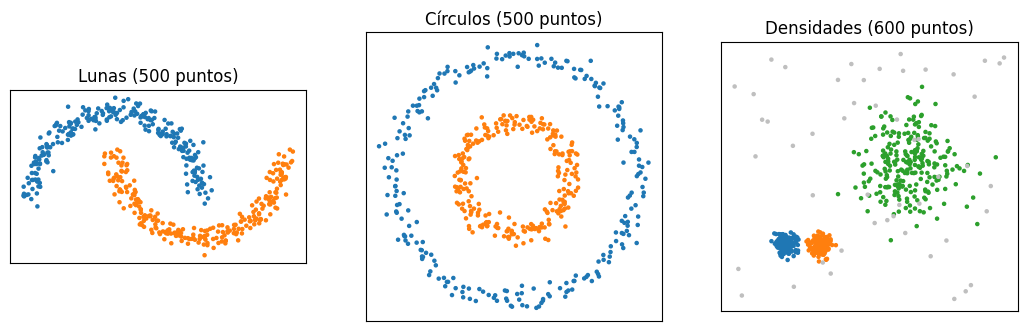

In [2]:
Xm, ym = make_moons(500, noise=0.07, random_state=0)
Xc, yc = make_circles(500, factor=0.45, noise=0.05, random_state=0)
Xb, yb = make_blobs([150, 150, 250], centers=[[0, 0], [1.3, 0], [4.5, 3]],
                    cluster_std=[0.2, 0.2, 1.0], random_state=0)
ruido = np.random.default_rng(0).uniform([-2, -2], [8, 7], (50, 2))
Xd, yd = np.r_[Xb, ruido], np.r_[yb, -np.ones(50, int)]   # el ruido tiene etiqueta -1
datos = {"Lunas": (Xm, ym), "Círculos": (Xc, yc), "Densidades": (Xd, yd)}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (nombre, (X, y)) in zip(axes, datos.items()):
    dibujar(ax, X, y, f"{nombre} ({len(X)} puntos)")
plt.show()

## Paso 2: elegir $\varepsilon$ para DBSCAN

Gráfica de k-distancia con `min_samples = 10`: la distancia de cada punto a su 10.º vecino, ordenada.
El codo sugiere $\varepsilon$.

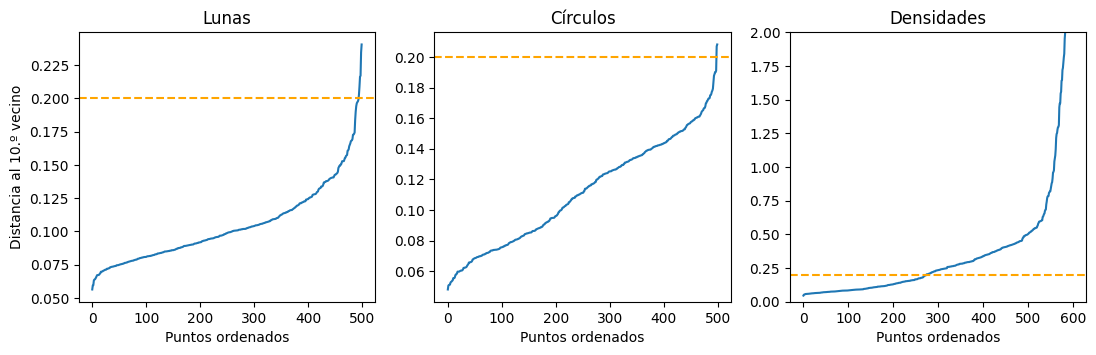

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (nombre, (X, y)) in zip(axes, datos.items()):
    d = np.sort(NearestNeighbors(n_neighbors=10).fit(X).kneighbors(X)[0][:, -1])
    ax.plot(d); ax.axhline(0.2, ls="--", color="orange"); ax.set_title(nombre)
    ax.set_xlabel("Puntos ordenados")
axes[2].set_ylim(0, 2); axes[0].set_ylabel("Distancia al 10.º vecino")
plt.show()

## Paso 3: DBSCAN con densidades distintas

Barrido de $\varepsilon$ en el conjunto de densidades, comparado con HDBSCAN.

In [4]:
X, y = datos["Densidades"]
filas = []
for eps in np.round(np.arange(0.1, 1.01, 0.05), 2):
    z = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
    filas.append((eps, round(adjusted_rand_score(y, z), 2), len(set(z) - {-1}), (z == -1).sum()))
barrido = pd.DataFrame(filas, columns=["eps", "ARI", "grupos", "ruido"])
z_h = HDBSCAN(min_cluster_size=15).fit_predict(X)
print("HDBSCAN: ARI", round(adjusted_rand_score(y, z_h), 2), "| ruido", (z_h == -1).sum())
barrido

HDBSCAN: ARI 0.91 | ruido 47


c:\Users\raul.perez\AppData\Local\anaconda3\envs\DS\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,eps,ARI,grupos,ruido
0,0.10,0.38,2,402
1,0.15,0.72,2,323
2,0.20,0.78,3,291
3,0.25,0.66,6,213
4,0.30,0.41,3,177
5,0.35,0.47,2,145
6,0.40,0.52,2,107
7,0.45,0.60,2,72
8,0.50,0.63,2,58
9,0.55,0.64,2,51


In [6]:
z = DBSCAN(eps=0.2, min_samples=10).fit_predict(X)
print("DBSCAN eps=0.2"); print(pd.crosstab(y, z, rownames=["verdadero"], colnames=["DBSCAN"]))
print("\nHDBSCAN"); print(pd.crosstab(y, z_h, rownames=["verdadero"], colnames=["HDBSCAN"]))

DBSCAN eps=0.2
DBSCAN      -1    0    1   2
verdadero                   
-1          50    0    0   0
 0           3  147    0   0
 1           2    0  148   0
 2         236    0    0  14

HDBSCAN
HDBSCAN    -1    0    1    2
verdadero                   
-1         35   15    0    0
 0          4    0  146    0
 1          6    0    0  144
 2          2  248    0    0


## Paso 4: los cuatro métodos en los tres conjuntos

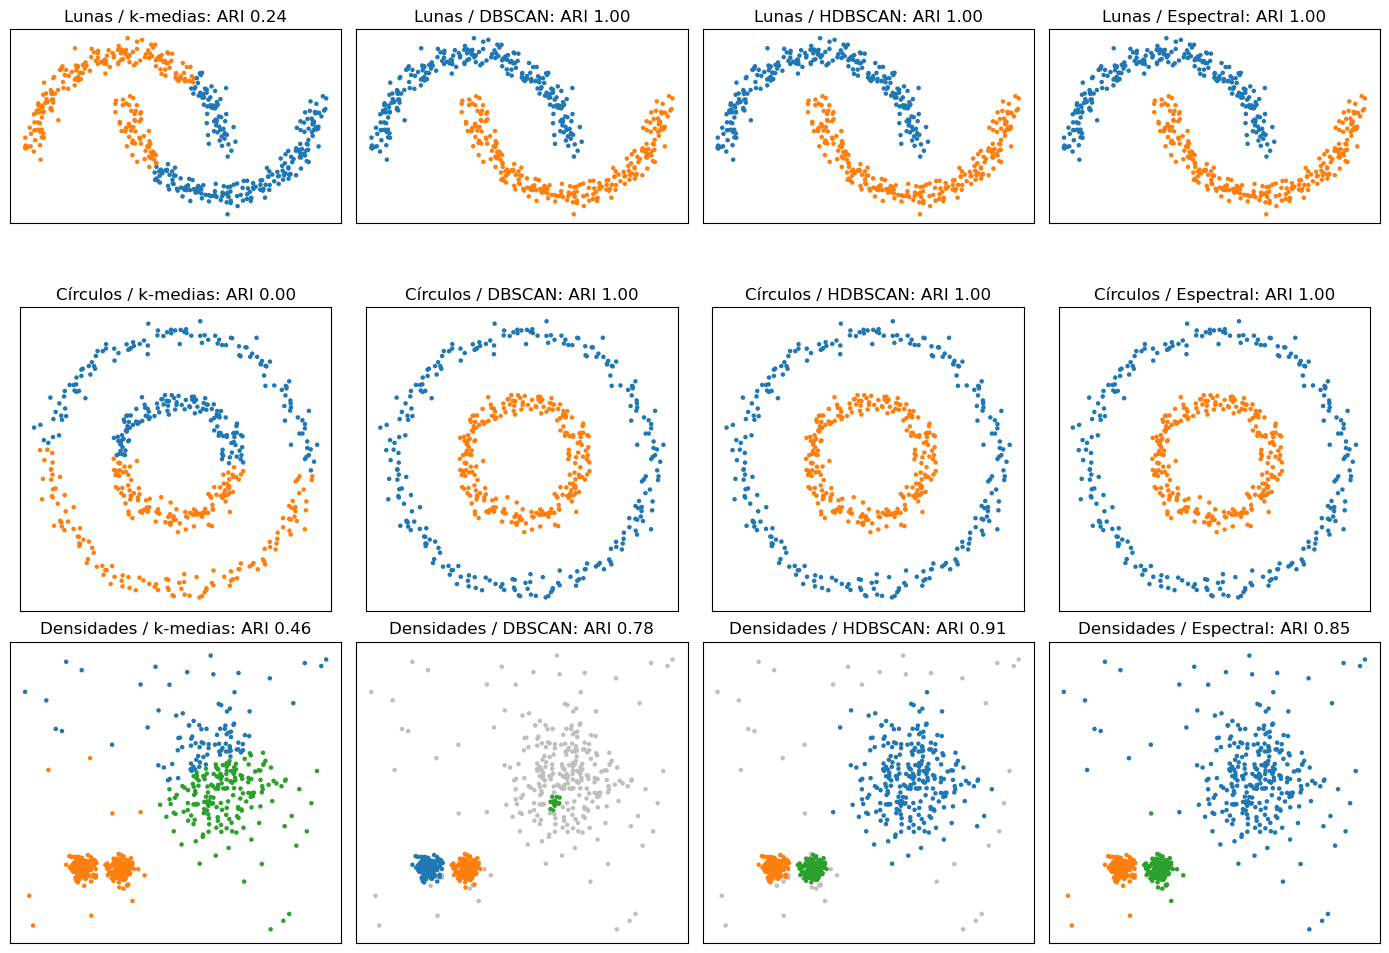

,k-medias,DBSCAN,HDBSCAN,Espectral
Lunas,0.24,1.00,1.00,1.00
Círculos,0.00,1.00,1.00,1.00
Densidades,0.46,0.78,0.91,0.85


In [6]:
resultados = {}
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for fila, (nombre, (X, y)) in enumerate(datos.items()):
    k = len(set(y) - {-1})
    modelos = {"k-medias": KMeans(k, n_init=10, random_state=0),
               "DBSCAN": DBSCAN(eps=0.2, min_samples=10),
               "HDBSCAN": HDBSCAN(min_cluster_size=15),
               "Espectral": SpectralClustering(k, affinity="nearest_neighbors",
                                               n_neighbors=10, random_state=0)}
    for col, (metodo, modelo) in enumerate(modelos.items()):
        z = modelo.fit_predict(X)
        a = round(adjusted_rand_score(y, z), 2) + 0.0
        resultados[(nombre, metodo)] = a
        dibujar(axes[fila, col], X, z, f"{nombre} / {metodo}: ARI {a:.2f}")
plt.tight_layout(); plt.show()
pd.Series(resultados).unstack().loc[list(datos), ["k-medias", "DBSCAN", "HDBSCAN", "Espectral"]]

## Conclusiones

* Con grupos no convexos de densidad parecida (lunas, círculos), DBSCAN, HDBSCAN y espectral recuperan
  los grupos; k-medias no.
* La gráfica de k-distancia da un buen $\varepsilon$ cuando tiene un codo claro; si no lo tiene, las
  densidades son distintas y ningún $\varepsilon$ basta.
* HDBSCAN resuelve las densidades distintas con un parámetro fácil de interpretar
  (`min_cluster_size`) y además marca el ruido.
* El agrupamiento espectral separa bien los grupos, pero necesita $K$ y no detecta ruido.